# 05 — Pelatihan Baseline DenseNet-121 (exp_005)

Transfer learning DenseNet-121 (bobot ImageNet) ke **7 kelas** awan. Notebook ini
merangkai modul di `src/` + config `configs/experiments/exp_005_densenet121.yaml`
supaya Anda bisa **menjalankan dan memantau pelatihan sendiri**.

Hyperparameter **sama persis** dengan baseline AlexNet (exp_006) — hanya
**arsitektur** yang berbeda (nilai diwarisi dari `configs/base.yaml`, berlaku
exp_005–009). Lihat `docs/pelatihan/densenet121/BASELINE_DENSENET121.md`.
Jalankan sel dari atas ke bawah.

**Catatan:**
- torch build **CUDA cu121 sudah terpasang** (GPU RTX 4060 Laptop 8 GB); Sel 1
  harus menampilkan `cuda True`. Sel "0. GPU" hanya cadangan bila pindah env.
- **DenseNet-121**: 4 *dense block* + *transition layer*; lapisan klasifikasi akhir
  satu `Linear(1024 → 7)` menggantikan head ImageNet 1000. Berbeda dari AlexNet,
  DenseNet torchvision **tidak** punya dropout FC bawaan; regularisasi datang dari
  `feature_extraction` (backbone beku) + train yang sudah seimbang.
- Dataset ada di drive USB eksternal yang kadang read-error transien; loader
  sudah retry baca 3x (lihat `src/datasets/cloud_dataset.py`).
- `pretrained=True` mengunduh bobot ImageNet DenseNet-121 (~30 MB) sekali saat pertama.

## 0. (Opsional) Pasang torch GPU (CUDA cu121)

Jalankan sel berikut **hanya** jika `cuda=False` di Sel 1 dan Anda ingin latih di
GPU. Unduhan ~2,5 GB. Setelah selesai, **restart kernel** lalu ulangi dari Sel 1.

In [1]:
# Hapus tanda komentar untuk memasang build GPU (cu121), lalu restart kernel:
# %pip install --force-reinstall --no-deps torch==2.1.1+cu121 torchvision==0.16.1+cu121 --index-url https://download.pytorch.org/whl/cu121

## 1. Setup & cek perangkat

In [2]:
import os, sys
from pathlib import Path

# Pastikan berjalan dari akar repo (folder yang memuat src/).
REPO = Path.cwd()
if not (REPO / "src").exists() and (REPO.parent / "src").exists():
    REPO = REPO.parent
os.chdir(REPO)
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

import torch
print("repo   :", REPO)
print("torch  :", torch.__version__)
print("cuda   :", torch.cuda.is_available(),
      "(" + torch.cuda.get_device_name(0) + ")" if torch.cuda.is_available() else "(CPU)")

repo   : d:\n8n-logsiswaparalayang\Jurnal\CitraAwan
torch  : 2.1.1+cu121
cuda   : True (NVIDIA GeForce RTX 4060 Laptop GPU)


## 2. Konfigurasi run

Ubah variabel di bawah sesuai kebutuhan, lalu jalankan.
- `EPOCHS=None` memakai nilai config (200). Untuk uji cepat, set `EPOCHS=1`.
- `BATCH_SIZE=8` untuk 512×512 di GPU 8 GB (RTX 4060 Laptop). **DenseNet-121 lebih
  berat memori daripada AlexNet** — bila OOM, turunkan ke 4.

**Soal kecepatan (penting):** GPU bukan penghambat — pelatihan ini **I/O-bound**
karena membaca JPEG 512×512 dari disk USB. Dengan `NUM_WORKERS=0` (aman di Jupyter
Windows) laju per-epoch lambat. Untuk jauh lebih cepat, latih lewat terminal
dengan pemuatan paralel:
`python scripts/train.py --config configs/experiments/exp_005_densenet121.yaml --batch-size 8`
sambil menaikkan `training.num_workers` (mis. 4) di config — `DataLoader` worker
>0 sering tidak stabil di dalam notebook Windows, jadi di sini default 0.

In [3]:
from src.utils.config import load_config, set_seed, resolve_device

CONFIG_PATH = "configs/experiments/exp_005_densenet121.yaml"
EPOCHS      = None   # None = pakai config (200); atau mis. 1 untuk uji cepat
BATCH_SIZE  = 8      # 512x512 @ 8 GB VRAM; turunkan ke 4 bila OOM (DenseNet lebih berat)
NUM_WORKERS = 0      # 0 = aman di Jupyter Windows; naikkan hanya via terminal runner
DEVICE      = "auto" # "auto" | "cpu" | "cuda"

cfg = load_config(CONFIG_PATH)
if EPOCHS is not None:
    cfg["training"]["epochs"] = EPOCHS
cfg["training"]["batch_size"] = BATCH_SIZE
cfg["training"]["num_workers"] = NUM_WORKERS
set_seed(cfg["seed"])
device = resolve_device(DEVICE)
name = cfg["name"]
print(f"eksperimen {name} | device {device} | epochs {cfg['training']['epochs']} "
      f"| batch {BATCH_SIZE} | workers {NUM_WORKERS}")

eksperimen exp_005_densenet121 | device cuda | epochs 200 | batch 8 | workers 0


## 3. Data (train seimbang 21.000 / val 1.851 / test 9.000)

In [4]:
from src.datasets.cloud_dataset import build_dataloader

train_loader = build_dataloader("train", cfg)
val_loader   = build_dataloader("val", cfg)
test_loader  = build_dataloader("test", cfg)
print("batches -> train:", len(train_loader), "| val:", len(val_loader), "| test:", len(test_loader))

batches -> train: 2625 | val: 232 | test: 1125


## 4. Model (DenseNet-121 pra-latih ImageNet, head -> 7 kelas)

In [5]:
from src.models.baseline import build_model, count_parameters

model = build_model(
    cfg["model"]["architecture"],
    num_classes=cfg["data"]["num_classes"],
    pretrained=bool(cfg["model"]["pretrained"]),
    finetune=cfg["model"]["finetune"],
)
total, trainable = count_parameters(model)
print(f'{cfg["model"]["architecture"]} | finetune={cfg["model"]["finetune"]} | '
      f'param total {total:,} | trainable {trainable:,}')
# DenseNet-121: lapisan klasifikasi akhir satu Linear(1024 -> 7) menggantikan head ImageNet 1000.
print("head keluaran:", model.classifier)

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to C:\Users\jardm/.cache\torch\hub\checkpoints\densenet121-a639ec97.pth
100%|██████████| 30.8M/30.8M [00:12<00:00, 2.58MB/s]


densenet121 | finetune=feature_extraction | param total 6,961,031 | trainable 7,175
head keluaran: Linear(in_features=1024, out_features=7, bias=True)


## 5. Pelatihan — pantau per epoch (progress bar pkbar)

Sel ini melatih model dengan **progress bar gaya Keras (pkbar)**: tiap epoch
punya bar per-batch yang berjalan langsung memperlihatkan `loss`, lalu di akhir
baris ditutup metrik validasi (`train_loss`, `val_loss`, `val_macro_f1`,
`val_bal_acc`, `val_acc`). Epoch terbaik (val_macro_f1) ditandai barisnya.
Checkpoint terbaik disimpan otomatis ke `checkpoints/<nama>/best.pt`.

Sel ini berjalan lama — biarkan dan amati barnya maju.

In [ ]:
from pathlib import Path
from src.training.trainer import fit

ckpt = Path(cfg["checkpoint"]["dir"]) / name / "best.pt"
# progress=True -> progress bar pkbar per-batch + metrik validasi di akhir baris.
result = fit(model, train_loader, val_loader, cfg, device, ckpt, progress=True)
print(f"\nSELESAI. best_epoch={result.best_epoch} | best val_macro_f1={result.best_metric:.4f}")
print("checkpoint:", ckpt)

Backend agg is non-interactive backend. Turning interactive mode off.
Epoch: 1/200
 653/2625 [==>.............] - ETA: 13:44 - loss: 0.6034

### 5b. Ringkasan riwayat (tabel + grafik)

In [7]:
import pandas as pd

hist = pd.DataFrame([r.__dict__ for r in result.history]).set_index("epoch")
display(
    hist.round(4).style.apply(
        lambda s: ["background-color: #b7e1cd" if i == result.best_epoch - 1 else ""
                for i in range(len(s))],
        axis=0,
    )
)
ax = hist[["train_loss", "val_loss"]].plot(title=f"{name}: loss per epoch", figsize=(7, 4))
ax.set_xlabel("epoch"); ax.set_ylabel("loss")
hist[["val_macro_f1", "val_balanced_accuracy", "val_accuracy"]].plot(
    title=f"{name}: metrik validasi per epoch", figsize=(7, 4)
).set_xlabel("epoch")

,train_loss,val_loss,val_macro_f1,val_balanced_accuracy,val_accuracy
epoch,,,,,
1,1.267500,0.888900,0.641600,0.644100,0.673700
2,0.971000,0.799600,0.653800,0.659200,0.690400
3,0.885600,0.755400,0.658400,0.651700,0.692600
4,0.847100,0.720400,0.689200,0.684000,0.712600
5,0.821000,0.706100,0.694400,0.689100,0.716400
6,0.797800,0.684800,0.710500,0.710500,0.727700
7,0.781400,0.667400,0.721000,0.720900,0.739600
8,0.763400,0.653400,0.733400,0.738900,0.745500
9,0.757700,0.660900,0.716400,0.708700,0.734700


Text(0.5, 0, 'epoch')

## 6. Evaluasi test (sekali) + tulis artefak

Test dievaluasi **sekali** memakai checkpoint terbaik (dipilih dari val, bukan
test). Artefak ditulis ke `experiments/<nama>/`: `config.yaml`, `metrics.json`,
`training_history.csv`, `classification_report.txt`, `confusion_matrix.png`,
`notes.md`.

In [8]:
import torch
from src.training.trainer import build_criterion, evaluate
from src.evaluation.metrics import compute_metrics
from scripts.train import write_outputs

state = torch.load(ckpt, map_location=device)
model.load_state_dict(state["model_state_dict"])

_, y_true, y_pred = evaluate(model, test_loader, build_criterion(cfg, device), device)
test_metrics = compute_metrics(y_true, y_pred, cfg["data"]["num_classes"])
print(f"TEST macro-F1 {test_metrics['macro_f1']:.4f} | "
      f"balanced acc {test_metrics['balanced_accuracy']:.4f} | acc {test_metrics['accuracy']:.4f}")

exp_dir = Path(cfg["output"]["experiments_dir"]) / name
write_outputs(exp_dir, cfg, result, test_metrics, y_true, y_pred)
print("artefak ->", exp_dir)

TEST macro-F1 0.6798 | balanced acc 0.6586 | acc 0.7138
artefak -> experiments\exp_005_densenet121


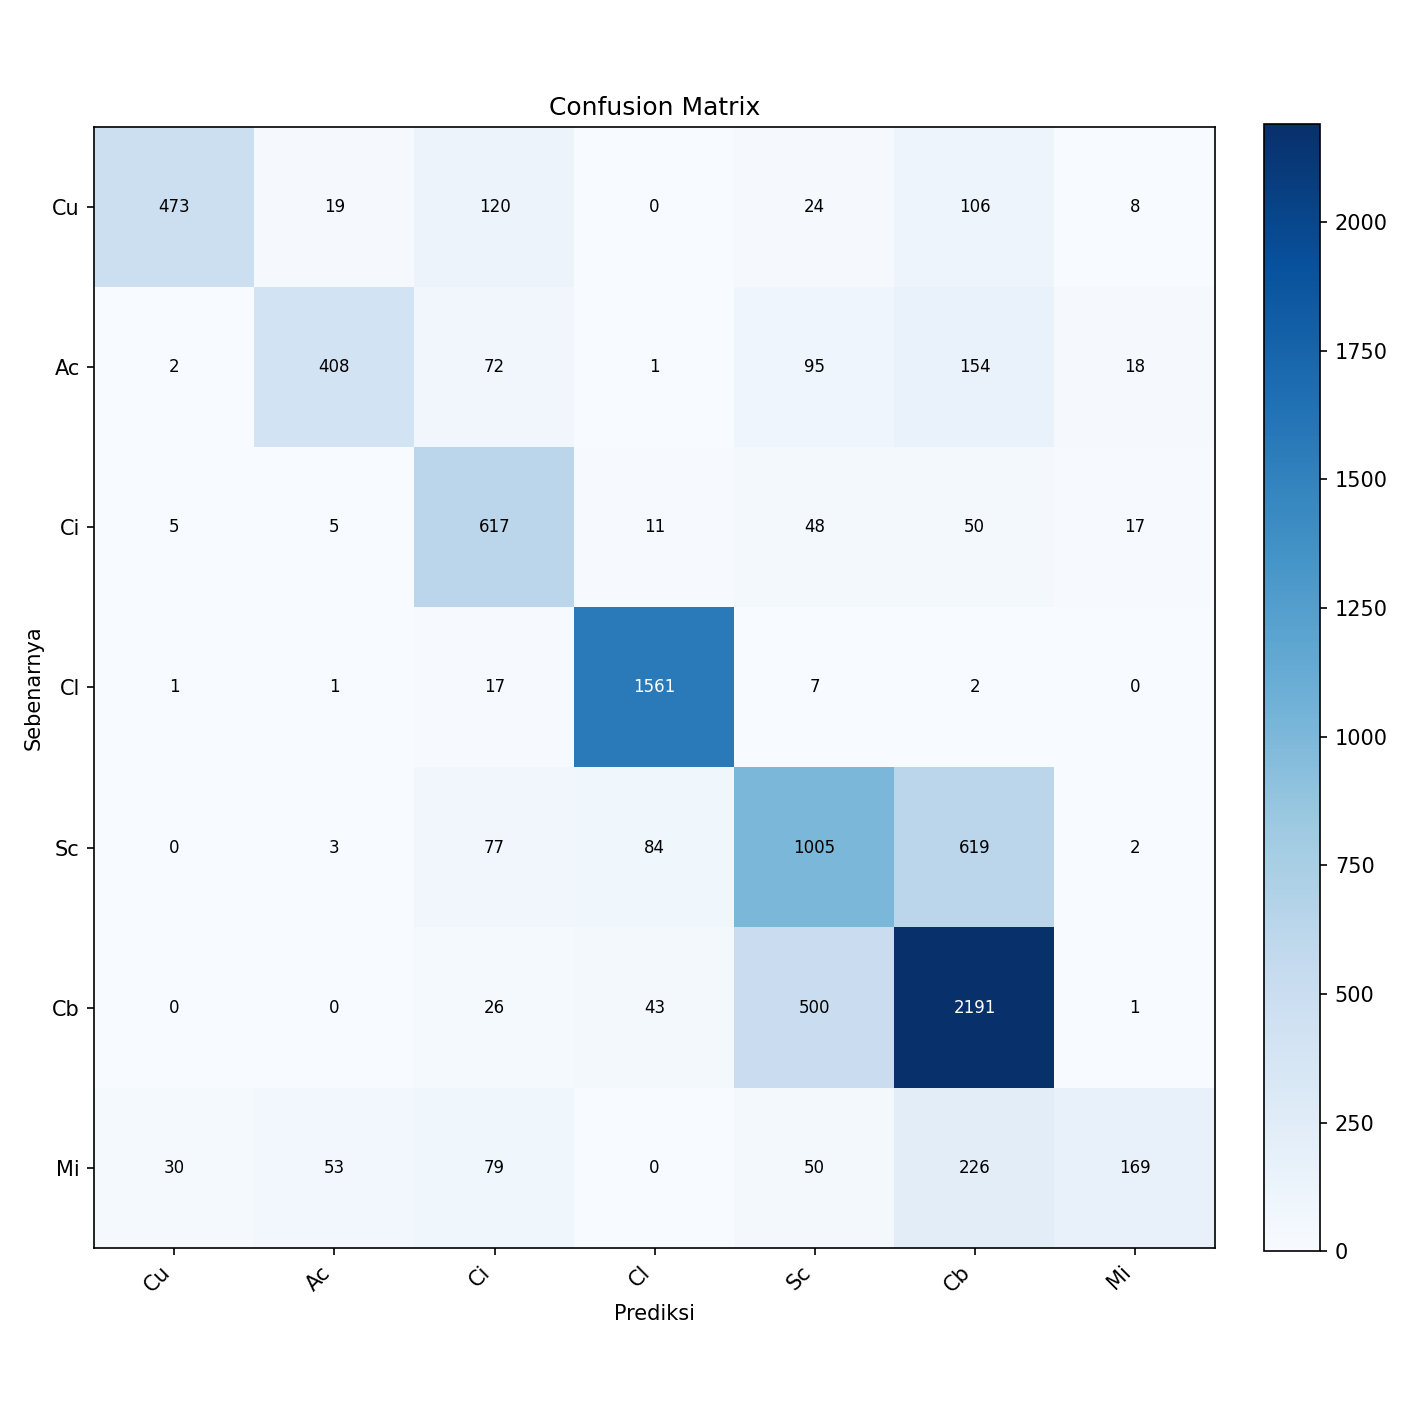

In [9]:
# Lihat confusion matrix yang baru disimpan
from IPython.display import Image as IPImage
IPImage(filename=str(exp_dir / "confusion_matrix.png"))